# Notebook 3: Will the idea work?

The idea is a check that a support agent does before sending a ticket to engineering.

Before building it, we test two things:

1. Can we guess **which** tickets will come back? Then we could warn only on those.
2. If the check stops some tickets from coming back, **how much** does it help?

## Step 1: Load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the ticket file
df = pd.read_csv("../backend/data/rideops_support_tickets.csv")

# Turn the date columns into real dates
for col in ["created_at", "first_response_at", "first_closed_at", "final_closed_at"]:
    df[col] = pd.to_datetime(df[col])

# The data was pulled at the end of 30 Sep 2026. We treat that as "now".
now = pd.Timestamp("2026-09-30 23:59")

# Simple yes / no columns
df["escalated"] = df["escalated_to_eng"] == "Yes"
df["is_open"] = df["status"] != "Closed"
df["reopened"] = df["reopen_count"] > 0

# "Bounced" = sent to engineering, but engineering did not fix it
df["eng_outcome"] = df["eng_outcome"].fillna("")
df["bounced"] = df["escalated"] & (df["eng_outcome"] != "Fixed")

# Hours from created to closed (empty if the ticket is still open)
df["hours_to_close"] = (df["final_closed_at"] - df["created_at"]).dt.total_seconds() / 3600

# Same, but open tickets are counted up to "now"
end_time = df["final_closed_at"].fillna(now)
df["age_hours"] = (end_time - df["created_at"]).dt.total_seconds() / 3600

# Replace numbers with N, so similar problems get the same name
df["issue_type"] = df["description"].str.replace(r"\d+", "N", regex=True)

print("Tickets:", len(df))

Tickets: 1444


## Step 2: Can we guess which tickets will come back?

To test a guess fairly, we must test it on tickets it has not seen. So:

- We **learn** from tickets sent to engineering in July and August.
- We **test** on tickets sent in September.

The rule: *if this kind of ticket came back 60% of the time or more in July and August, flag it.*

In [2]:
sent_to_eng = df[df["escalated"]]

learn = sent_to_eng[sent_to_eng["created_at"] < "2026-09-01"]
test = sent_to_eng[sent_to_eng["created_at"] >= "2026-09-01"]

# If we flag every ticket, how often are we right?
normal_rate = test["bounced"].mean()

print("Tickets to learn from:", len(learn))
print("Tickets to test on:", len(test))
print("In the test tickets,", round(normal_rate * 100), "% came back anyway")

Tickets to learn from: 297
Tickets to test on: 189
In the test tickets, 59 % came back anyway


That last number is important. **59% come back anyway.** A rule is only useful if the tickets it
flags come back clearly more often than 59%.

Now we try the rule four ways: by type of problem, by category, by agent, and by type of problem
and agent together.

In [3]:
# One more column: the type of problem and the agent together
learn = learn.assign(issue_and_agent=learn["issue_type"] + " | " + learn["assigned_agent"])
test = test.assign(issue_and_agent=test["issue_type"] + " | " + test["assigned_agent"])

results = []

for col in ["issue_type", "category", "assigned_agent", "issue_and_agent"]:
    # How often did each group come back in July and August?
    past = learn.groupby(col)["bounced"].agg(["mean", "count"])

    # Keep groups with at least 3 tickets where 60% or more came back
    risky_groups = past[(past["count"] >= 3) & (past["mean"] >= 0.6)].index

    # Flag the September tickets that belong to those groups
    flagged = test[test[col].isin(risky_groups)]

    results.append({
        "rule": "same " + col,
        "tickets_flagged": len(flagged),
        "flagged_that_came_back_%": round(flagged["bounced"].mean() * 100),
    })

results = pd.DataFrame(results)
results

,rule,tickets_flagged,flagged_that_came_back_%
0,same issue_type,62,56
1,same category,54,57
2,same assigned_agent,69,65
3,same issue_and_agent,22,73


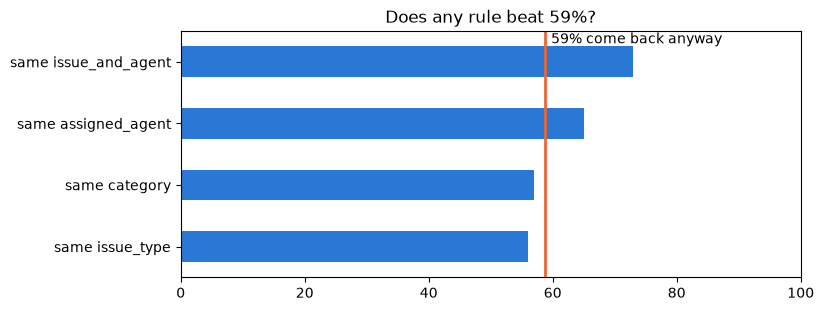

In [4]:
results.plot(kind="barh", x="rule", y="flagged_that_came_back_%", color="#2a78d6",
             legend=False, figsize=(8, 3.2), title="Does any rule beat 59%?")
plt.axvline(normal_rate * 100, color="#eb6834", linewidth=2)
plt.text(normal_rate * 100 + 1, 3.3, "59% come back anyway")
plt.xlim(0, 100)
plt.ylabel("")
plt.show()

**What we see**

- By type of problem: 56%. That is not better than 59%.
- By category: 57%. Also not better.
- By agent: 65%. A little better. This is the Rahul T effect from notebook 1.
- By type of problem and agent together: 73%, but it flags only 22 tickets. That is too few to trust,
  and it misses most of the tickets that come back.

**We cannot guess which tickets will come back from the type of problem.**

One limit: we only tried simple rules. With this little data (189 test tickets) a bigger model would
be easy to fool, so we did not build one.

## Step 3: Can we spot duplicates automatically?

56 tickets came back as "duplicate of known issue". One idea: if the same kind of problem was sent to
engineering in the last 7 days, warn the agent that it is probably already known.

In [5]:
seen_recently = []

for index, row in test.iterrows():
    same_problem = sent_to_eng["issue_type"] == row["issue_type"]
    before_this = sent_to_eng["created_at"] < row["created_at"]
    within_7_days = sent_to_eng["created_at"] >= row["created_at"] - pd.Timedelta(days=7)

    earlier_tickets = sent_to_eng[same_problem & before_this & within_7_days]
    seen_recently.append(len(earlier_tickets) > 0)

test = test.copy()
test["seen_recently"] = seen_recently
test["is_duplicate"] = test["eng_outcome"] == "Duplicate of known issue"

warned = test[test["seen_recently"]]

print("Tickets we would warn on:", len(warned), "of", len(test))
print("Of those, really duplicates:", round(warned["is_duplicate"].mean() * 100), "%")
print("Duplicates among all test tickets:", round(test["is_duplicate"].mean() * 100), "%")

Tickets we would warn on: 129 of 189
Of those, really duplicates: 17 %
Duplicates among all test tickets: 14 %


**What we see**

The warning would show on two thirds of all tickets, and it is right only 17% of the time. Without
any rule, 14% are duplicates. So this does not work either.

### What we changed because of these tests

- The tool does **not** try to guess risky tickets. More than half come back, so the check runs on
  **every** ticket sent to engineering.
- The checklist is built from the **reasons** engineering gives when it sends a ticket back.
- Duplicates are handled by a **list of known issues that engineering keeps**, not by a guess.

One note: this is made-up data. Real tickets have longer text and may be easier to guess.

## Step 4: If the check works, how much does it help?

This is a "what if". It is not a measurement.

For every ticket that came back, we imagine what would have happened with a good check:

| Why it came back | What happens instead | Time we assume |
|---|---|---|
| Settings problem, or a how-to question | Support solves it | Normal support time for that category |
| Not enough information, or could not see the problem | One clean trip to engineering | Normal time for a one-trip fix |
| Duplicate | Linked to the known issue | Same as before |

A ticket is never made slower than it really was.

In [6]:
# Normal time for support to solve each category
support_time = df[~df["escalated"]].groupby("category")["hours_to_close"].median()

# Normal time for a fix that needed only one trip
one_trip_fixes = df[(df["eng_outcome"] == "Fixed") & (df["eng_handoffs"] == 1)]
one_trip_time = one_trip_fixes["hours_to_close"].median()
print("Normal time for a one-trip fix:", round(one_trip_time, 1), "hours")

# Start with the real time, then change it for tickets that came back
df["what_if_hours"] = df["age_hours"]

support_could_solve = df["eng_outcome"].isin(["Config issue - returned to L1", "Not a bug - how-to"])
df.loc[support_could_solve, "what_if_hours"] = df.loc[support_could_solve, "category"].map(support_time)

needs_one_trip = df["eng_outcome"].isin(["Insufficient info - returned to L1", "Not reproducible"])
df.loc[needs_one_trip, "what_if_hours"] = one_trip_time

# Never slower than what really happened
df["what_if_hours"] = df[["what_if_hours", "age_hours"]].min(axis=1)

df["hours_saved"] = df["age_hours"] - df["what_if_hours"]

Normal time for a one-trip fix: 56.8 hours


In [7]:
# Hours saved for each reason, if every one of them was prevented
came_back = df[df["bounced"]]
saved_by_reason = came_back.groupby("eng_outcome").agg(
    tickets=("ticket_id", "count"),
    hours_saved=("hours_saved", "sum"),
)
saved_by_reason.sort_values("hours_saved", ascending=False).round(0)

,tickets,hours_saved
eng_outcome,,
Config issue - returned to L1,84,10442.0
Insufficient info - returned to L1,89,6973.0
Not a bug - how-to,24,1410.0
Not reproducible,22,477.0
Duplicate of known issue,56,0.0


We do not know how many tickets the check will really stop. So we try three cases: it stops 25%,
50% or 100% of them.

In [8]:
total_saved = df["hours_saved"].sum()
total_waiting = df["age_hours"].sum()

# Open tickets today, and the ones that would already be closed in the "what if"
open_now = df[df["is_open"]]
old_open = open_now[open_now["age_hours"] >= 48]
would_be_closed = open_now[open_now["what_if_hours"] < open_now["age_hours"]]
old_would_be_closed = old_open[old_open["what_if_hours"] < old_open["age_hours"]]

rows = []
for share in [0, 0.25, 0.5, 1.0]:
    rows.append({
        "check_stops": str(int(share * 100)) + "%",
        "open_over_48h": len(old_open) - share * len(old_would_be_closed),
        "all_open": len(open_now) - share * len(would_be_closed),
        "waiting_hours_saved": round(total_saved * share),
        "saved_as_%_of_all_waiting": round(total_saved * share / total_waiting * 100, 1),
    })

what_if = pd.DataFrame(rows)
what_if

,check_stops,open_over_48h,all_open,waiting_hours_saved,saved_as_%_of_all_waiting
0,0%,25.00,48.00,0,0.0
1,25%,21.75,44.75,4825,7.2
2,50%,18.50,41.50,9650,14.4
3,100%,12.00,35.00,19301,28.8


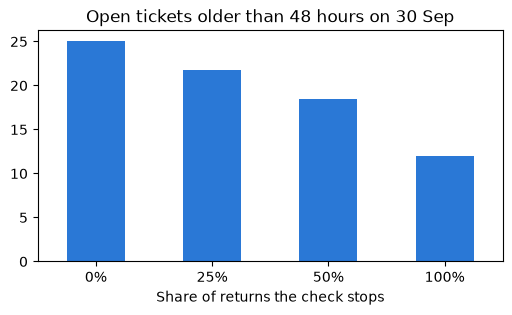

In [9]:
what_if.plot(kind="bar", x="check_stops", y="open_over_48h", color="#2a78d6", legend=False,
             figsize=(6, 3), title="Open tickets older than 48 hours on 30 Sep")
plt.xlabel("Share of returns the check stops")
plt.xticks(rotation=0)
plt.show()

**What we see**

If the check stops half of the returns:

- open tickets older than 48 hours go from **25 to 18.5**
- all open tickets go from 48 to 41.5
- about 9,650 waiting hours are removed (14% of all waiting time)

Most of the gain comes from two reasons: settings problems and missing information.

### What the tool does NOT fix

Even if the check stops every return, 35 tickets are still open (12 of them old). The pile does not
go back to July levels, because:

- 52% more tickets are coming in, and this tool does not reduce that
- a real engineering fix still takes about 65 hours

Those two need other work, and they go into the four-week plan.

## Summary

| Question | Answer |
|---|---|
| Can we guess which tickets come back? | No. 56% against 59% anyway |
| Can we spot duplicates automatically? | No. 17% against 14% anyway |
| So what does the tool do? | Runs a checklist on every ticket sent to engineering, and shows known issues |
| How much could it help? | If it stops half: old open tickets go from 25 to 18.5 |
| What is left? | More tickets coming in (+52%) and slow real fixes (about 65 hours) |
| How do we find the real effect? | Try it with a few agents and measure. The app logs every check for this |